# 02 · Датасет для моделі сонця

По годинах: **ціль** — середня генерація панелей з Deye (Вт), поруч — погода і положення сонця. Лише денні години з 23 гру 2024 (з цього дня працюють панелі). Час київський.

Тут — чи годині можна вірити: дірки і обрізане сонце. Ознаки — у `03_features`.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import data_io as io, dataset
plt.rcParams.update({'figure.figsize': (11, 3.5), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', None)

df = dataset.build()
df.to_parquet(io.DATA / 'dataset.parquet')
use = df.enough & ~df.clipped
pd.DataFrame({'годин': [len(df), int(use.sum()), int((~df.enough).sum()), int((df.enough & df.clipped).sum())]},
             index=['денних годин усього', 'для навчання', 'відкинуто: мало записів (< 6 з 12)', 'відкинуто: сонце обрізане'])

,годин
денних годин усього,8361
для навчання,5907
відкинуто: мало записів (< 6 з 12),69
відкинуто: сонце обрізане,2385


## Дірки

На сітці 5 хв дірки до 30 хв заповнені лінійно — середнім між сусідніми записами (`GAP_FILL`). Довші не латаємо: година йде в навчання, лише якщо в ній ≥ 6 справжніх записів з 12. Як розподілені години з малою кількістю записів:

In [2]:
MONTHS = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']
loc = df.index.tz_convert(io.TZ)
bad = (~df.enough).groupby([loc.year, loc.month]).sum()
bad = bad[bad > 0]
bad.index = [f'{MONTHS[m - 1]} {y}' for y, m in bad.index]
bad.rename('годин з малою кількістю записів').to_frame()

,годин з малою кількістю записів
тра 2025,1
чер 2025,1
лип 2025,11
вер 2025,4
лис 2025,6
січ 2026,26
лют 2026,7
чер 2026,5
лип 2026,1
сер 2026,7


## Обрізані години справді нижчі

При тій самій радіації обрізані години (червоні) мають меншу генерацію: батарея повна, інвертор віддав сонця рівно на дім. Тому в навчання їх не беремо.

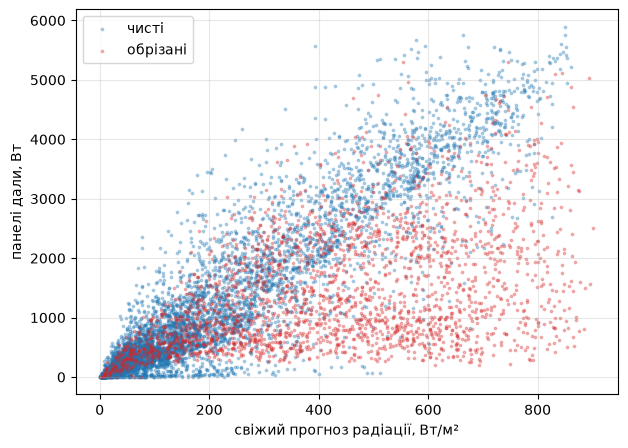

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
for flag, color, name in ((False, 'tab:blue', 'чисті'), (True, 'tab:red', 'обрізані')):
    s = df[df.enough & (df.clipped == flag)]
    ax.scatter(s.forecast__shortwave_radiation, s.pv_w, s=3, alpha=.3, c=color, label=name)
ax.set_xlabel('свіжий прогноз радіації, Вт/м²'); ax.set_ylabel('панелі дали, Вт'); ax.legend(); plt.show()

## Висновки

1. **Таблиця.** 8 361 денна година з 23 гру 2024; для навчання **5 907**. Відкинуто 69 годин з малою кількістю записів (обриви зв'язку, зокрема ожеледиця 26–29 січ 2026) разом із 3 годинами збою, і 2 385 обрізаних. Дірки до 30 хв заповнені лінійно.
2. **Обрізання — з 93 %, а не з 97 %.** Година обрізана, якщо батарея ≥ 93 % і мережа не потрібна хоча б пів години: інвертор уже притискає заряд і бере сонця рівно на дім. Перевірено в `07`: у таких годинах факт 0.58–0.91 від очікуваного, а з меншою часткою — як звичайно. Зі старою межею (97 %) ці години вчили модель, що «панелі слабкі після обіду».
3. **Обрізання видно на графіку**: при тій самій радіації червоні точки нижче. Без фільтра модель вирішила б, що панелі слабші, ніж є.